# 함정 3. APoT는 분포에 따라 이기기도 지기도 한다

4-bit magnitude + sign으로 양쪽 모두 31개 레벨을 사용한다. 분포별로 최적 클립을 찾은 뒤 균일 양자화와 APoT의 MSE를 비교한다. 각 비교에서는 레벨 배치만 바꾼다. 세 분포의 분산은 모두 1이며 Student-t의 자유도는 3이다.

꼬리 적분을 포함한다. Student-t에서 꼬리를 잘라 버리면 MSE가 과소 평가된다. 시드는 0 하나이며, 이 실험의 수치 적분은 결정적이다. 실행 시간은 환경 표에서 갱신된다. [학습 가이드](../docs/README.md#함정-3-apot는-분포에-따라-이기기도-지기도-한다).


In [1]:
import json
import os
import platform
import random
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
RESULTS = ROOT / "runs" / "m1"
FIGURES = ROOT / "docs" / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(RESULTS / ".matplotlib"))

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
generator = torch.Generator(device=DEVICE).manual_seed(SEED)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "svg.fonttype": "none", "svg.hashsalt": "quant-pitfalls"})
RUN_INFO = {"seed": SEED, "seeds": 1, "python": platform.python_version(), "torch": torch.__version__, "device": DEVICE, "integration_device": "cpu",
            "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None, "runtime_seconds": None}
STARTED = time.monotonic()
run_display = display(RUN_INFO, display_id=True)


{'seed': 0,
 'seeds': 1,
 'python': '3.11.15',
 'torch': '2.14.1+cu130',
 'device': 'cuda',
 'integration_device': 'cpu',
 'gpu': 'NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU',
 'runtime_seconds': 1.751}

In [2]:
from quant_pitfalls.analysis import expected_mse, optimal_clip
from quant_pitfalls.quant.apot import apot_fake_quant, apot_levels
from quant_pitfalls.quant.uniform import UniformSpec, fake_quant

levels = apot_levels(4, k=2)
uniform_levels = torch.linspace(0, 1, 16, dtype=torch.float64)
mag = UniformSpec(4, signed=False)
make_uniform = lambda alpha: (lambda x: x.sign() * fake_quant(x.abs(), alpha, mag))
make_apot = lambda alpha: (lambda x: apot_fake_quant(x, alpha, levels))
probe = torch.linspace(-25, 25, 10001, dtype=torch.float64)
for factory in [make_uniform, make_apot]:
    torch.testing.assert_close(factory(5.0)(probe.to(DEVICE)).cpu(), factory(5.0)(probe))
print("CPU/device quantization agreement:", DEVICE)
print("APoT levels / 48:", (levels * 48).round().to(torch.int64).tolist())
rows = []
for dist in ["gaussian", "laplace", "student_t"]:
    upper_u, upper_a = (20.0, 25.0) if dist == "student_t" else (8.0, 9.0)
    au, mu = optimal_clip(make_uniform, dist, 1.5, upper_u)
    aa, ma = optimal_clip(make_apot, dist, 1.5, upper_a)
    assert 1.5 < au < upper_u and 1.5 < aa < upper_a, "Extend the search bounds"
    rows.append({"distribution": dist, "uniform_alpha": au, "uniform_mse": mu,
                 "apot_alpha": aa, "apot_mse": ma, "ratio": ma / mu})
print("Distribution | uniform alpha, MSE | APoT alpha, MSE | ratio")
for row in rows:
    print(f"{row['distribution']:10s} | {row['uniform_alpha']:.5f}, {row['uniform_mse']:.7f} | {row['apot_alpha']:.5f}, {row['apot_mse']:.7f} | {row['ratio']:.5f}")


CPU/device quantization agreement: cuda
APoT levels / 48: [0, 1, 2, 3, 4, 6, 8, 9, 12, 16, 18, 24, 32, 33, 36, 48]


Distribution | uniform alpha, MSE | APoT alpha, MSE | ratio
gaussian   | 2.89996, 0.0036931 | 3.36150, 0.0060048 | 1.62596
laplace    | 4.31013, 0.0090851 | 5.70673, 0.0068599 | 0.75508
student_t  | 8.27420, 0.0764782 | 18.44907, 0.0390922 | 0.51116


## Student-t 적분 해상도 검증

위에서 구한 클립을 고정하고 적분 구간 수를 24,000에서 96,000으로 늘린다. 양자화 스텝보다 촘촘한 격자를 사용했을 때 결과가 유지되는지 확인한다. 항상 0을 출력하는 양자화기의 MSE도 계산해, 꼬리를 포함한 전체 분산 1이 보존되는지 확인한다.


Uniform: MSE 0.076478160 -> 0.076478297; relative difference 1.8e-06
APoT: MSE 0.039092214 -> 0.039093070; relative difference 2.19e-05
Full Student-t variance including tails: 1.0000000000


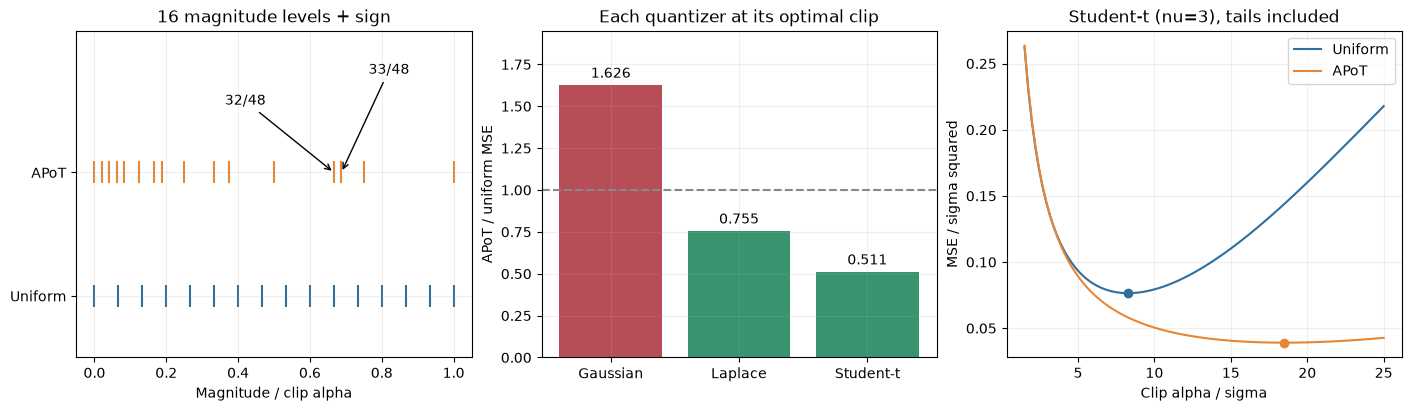

In [3]:
student = rows[-1]
convergence = []
for label, factory, alpha, limit in [("Uniform", make_uniform, student["uniform_alpha"], 40),
                                     ("APoT", make_apot, student["apot_alpha"], 50)]:
    coarse = expected_mse(factory(alpha), "student_t", limit=limit, intervals=24_000)
    refined = expected_mse(factory(alpha), "student_t", limit=limit, intervals=96_000)
    convergence.append({"quantizer": label, "coarse_mse": coarse, "refined_mse": refined, "relative_difference": abs(coarse - refined) / refined})
    print(f"{label}: MSE {coarse:.9f} -> {refined:.9f}; relative difference {abs(coarse - refined) / refined:.3g}")
variance_check = expected_mse(torch.zeros_like, "student_t")
print(f"Full Student-t variance including tails: {variance_check:.10f}")
alpha_grid = np.linspace(1.5, 25, 100)
student_uniform_curve = [expected_mse(make_uniform(float(a)), "student_t", limit=50) for a in alpha_grid]
student_apot_curve = [expected_mse(make_apot(float(a)), "student_t", limit=50) for a in alpha_grid]

fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
axes[0].scatter(uniform_levels.numpy(), np.zeros(16), marker="|", s=230, color="#2E6F9E", label="Uniform")
axes[0].scatter(levels.numpy(), np.ones(len(levels)), marker="|", s=230, color="#E68735", label="APoT")
for numerator, text_x, text_y in [(32, 0.42, 1.55), (33, 0.82, 1.8)]:
    axes[0].annotate(f"{numerator}/48", xy=(numerator / 48, 1), xytext=(text_x, text_y), arrowprops={"arrowstyle": "->"}, ha="center")
axes[0].set(xlabel="Magnitude / clip alpha", yticks=[0, 1], yticklabels=["Uniform", "APoT"], ylim=(-0.5, 2.15), title="16 magnitude levels + sign")
bars = axes[1].bar(["Gaussian", "Laplace", "Student-t"], [r["ratio"] for r in rows], color=["#B74D56", "#38936F", "#38936F"])
axes[1].axhline(1, linestyle="--", color="#888888")
axes[1].bar_label(bars, fmt="%.3f", padding=3)
axes[1].set(ylabel="APoT / uniform MSE", title="Each quantizer at its optimal clip")
axes[1].set_ylim(0, max(r["ratio"] for r in rows) * 1.2)
axes[2].plot(alpha_grid, student_uniform_curve, color="#2E6F9E", label="Uniform")
axes[2].plot(alpha_grid, student_apot_curve, color="#E68735", label="APoT")
axes[2].plot(student["uniform_alpha"], student["uniform_mse"], "o", color="#2E6F9E")
axes[2].plot(student["apot_alpha"], student["apot_mse"], "o", color="#E68735")
axes[2].set(xlabel="Clip alpha / sigma", ylabel="MSE / sigma squared", title="Student-t (nu=3), tails included")
axes[2].legend()
for ax in axes:
    ax.grid(alpha=0.2)
fig.savefig(FIGURES / "03_apot-vs-uniform.svg", metadata={"Date": None})
fig.savefig(RESULTS / "03_apot-vs-uniform.png", dpi=140)
plt.show()
report = {"magnitude_levels": levels.tolist(), "signed_level_count": 31, "comparisons": rows,
          "student_convergence": convergence, "student_variance_check": variance_check}


In [4]:
if DEVICE == "cuda":
    torch.cuda.synchronize()
report["run"] = {**RUN_INFO, "runtime_seconds": round(time.monotonic() - STARTED, 3)}
(RESULTS / "03_apot-vs-uniform.json").write_text(json.dumps(report, indent=2) + "\n")
run_display.update(report["run"])
print("Saved results: runs/m1/03_apot-vs-uniform.json")


Saved results: runs/m1/03_apot-vs-uniform.json


## 학습된 가중치의 첨도와 MSE

레이어별 가중치를 분산 1로 정규화하고 첨도를 기록한다. 부호를 포함해 31개인 같은 레벨 수와 각각의 최적 클립에서 균일/APoT의 MSE 비를 비교한다. 시드 0·1·2의 측정 기록을 사용한다.

기본 재현 명령은 저장소의 측정 기록을 사용한다. 새로운 학습 결과를 만들려면 [재현 방법](../docs/reproduction.md)의 체크포인트·학습 모드를 참고한다.


In [5]:
import json
import os
import platform
import time
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
RESULTS = ROOT / 'runs' / 'm3'
FIGURES = ROOT / 'docs' / 'figures'
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(RESULTS / '.matplotlib'))
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display, Markdown
plt.rcParams.update({'font.family':'DejaVu Sans','svg.fonttype':'none','svg.hashsalt':'quant-pitfalls'})
STARTED = time.perf_counter()
RUN_INFO = {'seeds':[0,1,2], 'python':platform.python_version(), 'torch':torch.__version__,
            'gpu':torch.cuda.get_device_name() if torch.cuda.is_available() else None, 'runtime_seconds':None}
INFO_HANDLE = display(RUN_INFO, display_id=True)
from quant_pitfalls.results import load_results
REPORT, DATA_SOURCE = load_results(ROOT, 'm3')
print('Training numerical input:', DATA_SOURCE)
print('Recorded training environment:', REPORT.get('reports', {}).get('float-baseline-s0', {}).get('environment'))
READY = REPORT.get('state') == 'complete'
if not READY:
    print('Selected training measurements are incomplete; plots are omitted.')

def save_figure(fig, name):
    fig.savefig(FIGURES / (name + '.svg'), bbox_inches='tight', metadata={'Date':None})
    fig.savefig(RESULTS / (name + '.png'), bbox_inches='tight', dpi=140)
    plt.show()

{'seeds': [0, 1, 2],
 'python': '3.11.15',
 'torch': '2.14.1+cu130',
 'gpu': 'NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU',
 'runtime_seconds': 0.631,
 'training_status': 'complete'}

Training numerical input: docs/results/m3.json.gz
Recorded training environment: {'torch': '2.14.1+cu130', 'gpu': 'NVIDIA GeForce RTX 5090'}


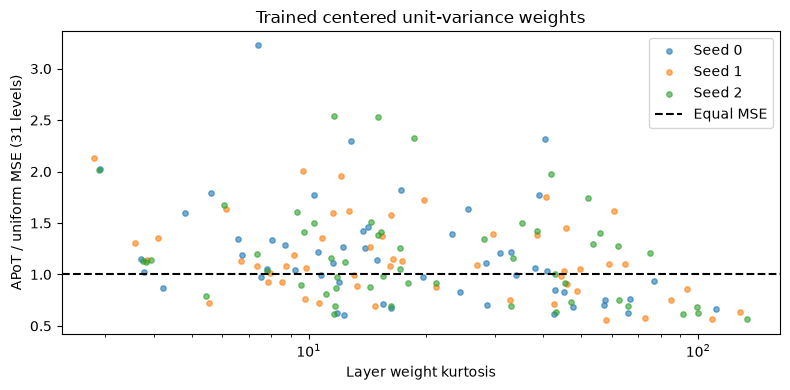

In [6]:
if READY:
    rows=REPORT['weight_distributions']['rows']
    fig,ax=plt.subplots(figsize=(8,4))
    for seed in (0,1,2):
        points=[r for r in rows if r['seed']==seed]
        ax.scatter([r['kurtosis'] for r in points],[r['mse_ratio'] for r in points],s=15,alpha=.6,label=f'Seed {seed}')
    ax.axhline(1,color='black',linestyle='--',label='Equal MSE')
    ax.set_xscale('log')
    ax.set_xlabel('Layer weight kurtosis')
    ax.set_ylabel('APoT / uniform MSE (31 levels)')
    ax.set_title('Trained centered unit-variance weights')
    ax.legend()
    fig.tight_layout()
    save_figure(fig,'03_weight-kurtosis')

In [7]:
RUN_INFO['runtime_seconds'] = round(time.perf_counter()-STARTED, 3)
RUN_INFO['training_status'] = REPORT['state']
INFO_HANDLE.update(RUN_INFO)

## 직접 확인하기

31개 레벨을 고정하고 Gaussian과 Laplace의 최적 MSE 비를 비교해 보자. 레벨이 0 근처에 모이는 것이 두 분포에 같은 이점을 주는가?
